# 2018〜2020 年に Q5 が負けた原因

`01_univariate` / `02_incremental_vs_comp_ew` の累積図では、どのスコアも 2018〜2020 年に **Q5 の対ベンチマーク超過が伸びない・下がる**。
シグナルが壊れたのか、市場の構造で負けたのかを切り分ける。

仮説:

- **H1 市場構造**: 超大型株への集中と中小型株の急落。等ウェイトの Q5 は中小型を多く持つので、シグナルの良し悪しと無関係に時価加重の BM に負ける
- **H2 シグナルの失効**: Q5 がユニバース平均より良い銘柄を選べていない
- **H3 特定のファクター・イベント**: セクター（NBFC 危機）やモメンタムの反転（コロナ後の急反発）

分解の考え方: $\text{Q5} - \text{BM} = \underbrace{(\text{EW ユニバース} - \text{BM})}_{\text{構造（スコアに依らない）}} + \underbrace{(\text{Q5} - \text{EW ユニバース})}_{\text{銘柄選択}}$。
ロングショートの Q5 − Q1 も選択の指標として見る。

**規約**: Q5 = スコア最上位（等ウェイト 5 分位）。リターンは `drtn`（配当込み、INR）と `srtn`（固有）。BM = MSCI India。
ファクター分解は GEMLT のエクスポージャー（月末 $t$）× 翌月のファクターリターン、残差を固有とする。

In [1]:
import matplotlib.pyplot as plt
import japanize_matplotlib  # noqa: F401  日本語ラベル用
import numpy as np
import pandas as pd

from alphaeval import InputStore, portfolio_returns, quantile_analysis

pd.set_option("display.width", 260)
pd.set_option("display.max_columns", 60)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3})

INPUT_ROOT = "../../input/msci_india_imi"
SCORES = {"comp_ew": "composite/comp_ew", "sleeve_a（リビジョン）": "composite/sleeve_a", "sleeve_b（モメンタム+CGO）": "composite/sleeve_b", "sleeve_d（規律）": "composite/sleeve_d", "hc_all": "hc/hc_all"}
MAIN = "comp_ew"
BENCHMARK = "msci_india"
RISK_MODEL = "GEMLT"
START, END = 200801, 202606
WINDOW = ("2018-05", "2019-08")   # comp_ew の Q5 EW − BM のピーク（2018-04 末）からボトム（2019-08 末）までのリターン月
VIEW = ("2016-01", "2021-12")
SECTOR_NAMES = {10: "エネルギー", 15: "素材", 20: "資本財", 25: "一般消費財", 30: "生活必需品", 35: "ヘルスケア", 40: "金融", 45: "情報技術", 50: "通信", 55: "公益", 60: "不動産"}

store = InputStore(INPUT_ROOT)
univ = store.universe(START, END)
bm = store.benchmark(BENCHMARK, START, END)
rets = {"drtn": store.returns(RISK_MODEL, "rtn", START, 202607), "srtn": store.returns(RISK_MODEL, "srtn", START, 202607)}
scores = {n: store.alpha(p, START, END).reindex(index=univ.index, columns=univ.columns).where(univ.notna()) for n, p in SCORES.items()}
ew_w = univ.notna().astype(float).where(univ.notna())
ew_w = ew_w.div(ew_w.sum(axis=1), axis=0)
bm_w = bm.reindex(index=univ.index, columns=univ.columns).fillna(0)
bm_w = bm_w.div(bm_w.sum(axis=1), axis=0)

def shade(ax):
    ax.axvspan(pd.Timestamp(WINDOW[0]) - pd.offsets.MonthEnd(1), pd.Timestamp(WINDOW[1]) + pd.offsets.MonthEnd(0), color="grey", alpha=0.15)
    ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-12-31"), color="orange", alpha=0.08)

## 1. 構造と選択への分解

各スコアの Q5（等ウェイト）について月次の差を計算し、年次合計と窓（灰色、2018-05〜2019-08）の合計を見る。橙は 2020 年。

[drtn] 窓 2018-05〜2019-08 の合計


,Q5 − BM,EW ユニバース − BM（構造）,Q5 − EW ユニバース（選択）,Q5 − Q1
comp_ew,-0.185,-0.293,0.108,0.293
sleeve_a（リビジョン）,-0.209,-0.293,0.085,0.165
sleeve_b（モメンタム+CGO）,-0.120,-0.293,0.173,0.389
sleeve_d（規律）,-0.247,-0.293,0.047,0.080
hc_all,-0.160,-0.293,0.133,0.232


[drtn] 年次合計（comp_ew）


,Q5 − BM,EW ユニバース − BM（構造）,Q5 − EW ユニバース（選択）,Q5 − Q1
2016,0.169,0.058,0.111,0.126
2017,0.238,0.148,0.090,0.108
2018,-0.114,-0.210,0.096,0.247
2019,-0.050,-0.146,0.095,0.229
2020,0.132,0.101,0.031,0.007
2021,0.367,0.131,0.235,0.329


[srtn] 窓 2018-05〜2019-08 の合計


,Q5 − BM,EW ユニバース − BM（構造）,Q5 − EW ユニバース（選択）,Q5 − Q1
comp_ew,-0.048,-0.103,0.055,0.141
sleeve_a（リビジョン）,-0.021,-0.103,0.083,0.093
sleeve_b（モメンタム+CGO）,-0.009,-0.103,0.095,0.183
sleeve_d（規律）,-0.062,-0.103,0.041,0.056
hc_all,-0.053,-0.103,0.051,0.073


[srtn] 年次合計（comp_ew）


,Q5 − BM,EW ユニバース − BM（構造）,Q5 − EW ユニバース（選択）,Q5 − Q1
2016,0.189,0.060,0.129,0.175
2017,0.135,0.101,0.034,0.002
2018,-0.056,-0.113,0.057,0.149
2019,0.033,-0.050,0.083,0.190
2020,0.136,0.149,-0.013,-0.028
2021,0.276,0.076,0.201,0.259


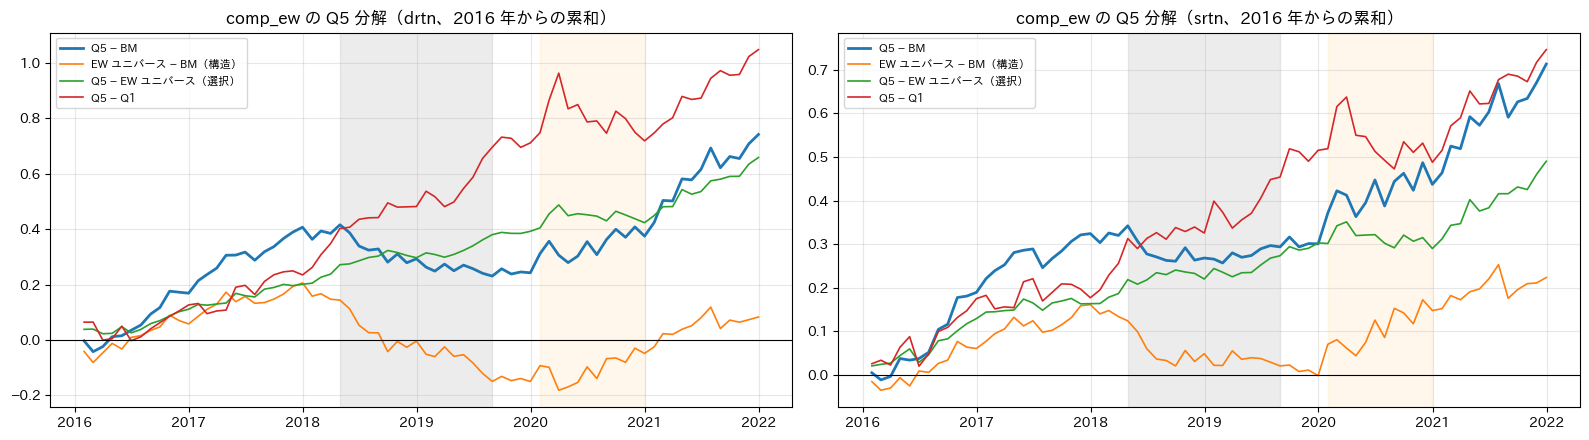

In [2]:
decomp = {kind: {} for kind in rets}
q_main = {}
for kind, r in rets.items():
    bmr = portfolio_returns(bm, r)
    ewr = portfolio_returns(ew_w, r)
    for n, s in scores.items():
        q = quantile_analysis(s, r, univ, 5)
        if n == MAIN:
            q_main[kind] = q
        decomp[kind][n] = pd.DataFrame({"Q5 − BM": q.returns[q.top] - bmr, "EW ユニバース − BM（構造）": ewr - bmr, "Q5 − EW ユニバース（選択）": q.returns[q.top] - ewr, "Q5 − Q1": q.returns["spread"]}).dropna()
for kind in rets:
    yr = {n: d.groupby(d.index.year).sum().loc[2016:2021] for n, d in decomp[kind].items()}
    win = {n: d.loc[WINDOW[0]:WINDOW[1]].sum() for n, d in decomp[kind].items()}
    print(f"[{kind}] 窓 {WINDOW[0]}〜{WINDOW[1]} の合計")
    display(pd.DataFrame(win).T.round(3))
    print(f"[{kind}] 年次合計（comp_ew）")
    display(yr[MAIN].round(3))

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
for ax, kind in zip(axes, ["drtn", "srtn"]):
    d = decomp[kind][MAIN].loc[VIEW[0]:VIEW[1]]
    for c in d.columns:
        ax.plot(d.index, d[c].cumsum(), label=c, linewidth=2 if c == "Q5 − BM" else 1.2)
    ax.axhline(0, color="k", linewidth=0.8)
    shade(ax)
    ax.set_title(f"comp_ew の Q5 分解（{kind}、2016 年からの累和）")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### 時価総額ウェイトの Q5 でも同じか

1 銘柄 5% 上限の時価総額ウェイトで同じ分解をする。構造 = 上限付き時価総額ウェイトのユニバース − BM。

In [3]:
r = rets["drtn"]
bmr = portfolio_returns(bm, r)
qc = quantile_analysis(scores[MAIN], r, univ, 5, 0.0, "size", size=univ, max_weight=0.05)
qu = quantile_analysis(scores[MAIN], r, univ, 1, 0.0, "size", size=univ, max_weight=0.05)
cw = pd.DataFrame({"Q5 CW − BM": qc.returns[qc.top] - bmr, "CW ユニバース（5% 上限）− BM（構造）": qu.returns[qu.top] - bmr, "Q5 CW − CW ユニバース（選択）": qc.returns[qc.top] - qu.returns[qu.top]}).dropna()
display(cw.groupby(cw.index.year).sum().loc[2016:2021].round(3))
print("窓の合計:", cw.loc[WINDOW[0]:WINDOW[1]].sum().round(3).to_dict())

,Q5 CW − BM,CW ユニバース（5% 上限）− BM（構造）,Q5 CW − CW ユニバース（選択）
2016,0.093,0.011,0.082
2017,0.233,0.040,0.193
2018,-0.106,-0.052,-0.054
2019,-0.045,-0.035,-0.009
2020,0.062,0.012,0.050
2021,0.315,0.040,0.275


窓の合計: {'Q5 CW − BM': -0.121, 'CW ユニバース（5% 上限）− BM（構造）': -0.077, 'Q5 CW − CW ユニバース（選択）': -0.044}


## 2. 市場構造（H1）

MSCI India の時価加重と等ウェイト、上位 10 銘柄とそれ以外、ユニバースの時価総額 5 分位（等ウェイト）の年次リターン（drtn）。

年次リターン（S1 = 小型 … S5 = 大型、ユニバース内の等ウェイト）


,BM 時価加重,BM 等ウェイト,BM 上位 10,BM 上位 10 以外,時価総額 S1,時価総額 S2,時価総額 S3,時価総額 S4,時価総額 S5,上位 10 の BM ウェイト
2014,0.264,0.343,0.212,0.329,0.512,0.546,0.670,0.502,0.296,0.532
2015,-0.016,-0.041,0.013,-0.047,-0.076,0.087,0.074,0.080,-0.068,0.522
2016,0.012,0.067,-0.046,0.072,0.076,0.064,0.026,0.036,0.061,0.492
2017,0.305,0.336,0.288,0.320,0.488,0.662,0.469,0.554,0.362,0.445
2018,0.015,-0.068,0.174,-0.110,-0.263,-0.217,-0.204,-0.176,-0.052,0.479
2019,0.102,0.011,0.208,-0.003,-0.132,-0.133,-0.043,0.037,0.005,0.524
2020,0.189,0.184,0.194,0.185,0.422,0.200,0.221,0.266,0.180,0.549
2021,0.290,0.340,0.225,0.355,0.413,0.585,0.496,0.468,0.361,0.479
2022,0.030,0.031,0.010,0.047,-0.024,0.011,-0.063,-0.009,0.036,0.458
2023,0.223,0.349,0.121,0.304,0.454,0.527,0.367,0.474,0.326,0.437


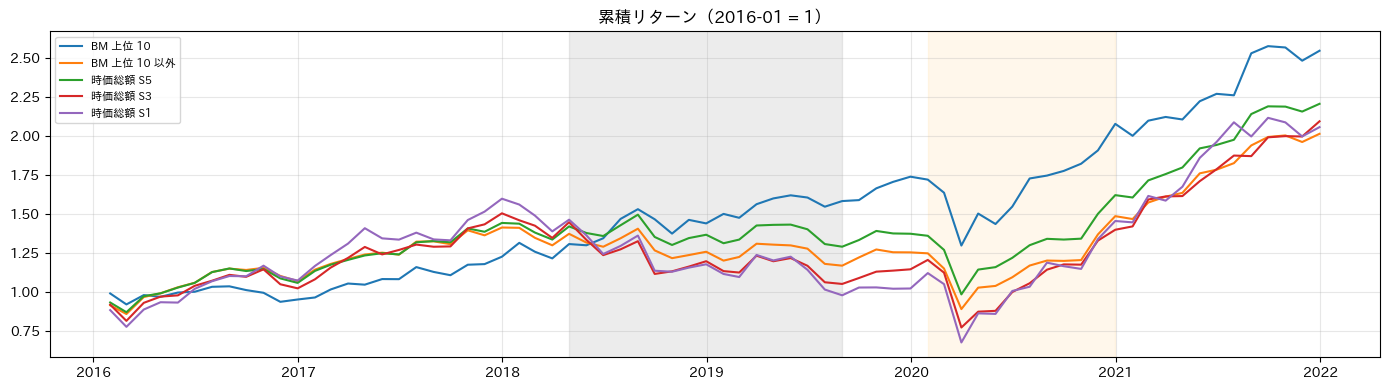

In [4]:
r = rets["drtn"]
w_prev = bm_w.reindex(r.index).shift(1).dropna(how="all")
rr = r.reindex(w_prev.index)
top10 = {d: w_prev.loc[d].nlargest(10).index for d in w_prev.index}
mk = pd.DataFrame({
    "BM 時価加重": (w_prev * rr).sum(axis=1),
    "BM 等ウェイト": rr.where(w_prev > 0).mean(axis=1),
    "BM 上位 10": pd.Series({d: (w_prev.loc[d, i] * rr.loc[d, i]).sum() / w_prev.loc[d, i].sum() for d, i in top10.items()}),
    "BM 上位 10 以外": pd.Series({d: (w_prev.loc[d].drop(i) * rr.loc[d].drop(i)).sum() / w_prev.loc[d].drop(i).sum() for d, i in top10.items()}),
    "上位 10 の BM ウェイト": pd.Series({d: w_prev.loc[d, i].sum() for d, i in top10.items()}),
})
u_prev = univ.reindex(r.index).shift(1)
rank = u_prev.rank(axis=1, pct=True)
for k, (lo, hi) in enumerate([(0, 0.2), (0.2, 0.4), (0.4, 0.6), (0.6, 0.8), (0.8, 1.01)], start=1):
    mk[f"時価総額 S{k}"] = r.where((rank > lo) & (rank <= hi)).mean(axis=1)
mk = mk.loc["2009":"2026"]
comp = lambda x: (1 + x).prod() - 1
yr = mk.drop(columns="上位 10 の BM ウェイト").groupby(mk.index.year).agg(comp)
yr["上位 10 の BM ウェイト"] = mk["上位 10 の BM ウェイト"].groupby(mk.index.year).mean()
print("年次リターン（S1 = 小型 … S5 = 大型、ユニバース内の等ウェイト）")
display(yr.loc[2014:2023].round(3))

fig, ax = plt.subplots(figsize=(14, 4))
v = mk.loc[VIEW[0]:VIEW[1]]
for c in ["BM 上位 10", "BM 上位 10 以外", "時価総額 S5", "時価総額 S3", "時価総額 S1"]:
    ax.plot(v.index, (1 + v[c]).cumprod(), label=c)
shade(ax)
ax.set_title("累積リターン（2016-01 = 1）")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

この期間のインド市場の主な出来事（背景として）:

- 2018-02 予算で長期キャピタルゲイン課税（10%）を再導入
- 2017-10 の SEBI 通達による投信のカテゴリ再編（2018 年に移行）。ラージキャップ投信は上位 100 社に 80% 以上を投資する義務
- 2018-09 IL&FS のデフォルトで NBFC の資金繰り危機。中小型・金融に売り
- 2020-03 コロナショックと全国ロックダウン、4 月以降の急反発

## 3. Q5 の対 BM ファクター分解（comp_ew）

Q5 等ウェイトのアクティブウェイト（Q5 − BM）にエクスポージャーを掛けて寄与を出す。

窓 2018-05〜2019-08 の合計


,Style,Industry,Country,ファクター計,固有,Q5 − BM
寄与,-0.1,-0.005,-0.03,-0.134,-0.051,-0.185


窓のファクター別寄与（下位 8 / 上位 5）


factor_id,SIZE,IND,RESVOL,SOFTWARE,EARNVAR,THRIFTS,BLDCNSTR,CHEMICAL,INOILGAS,LIQUIDTY,AUTOCOMP,BANKS,MOMENTUM
寄与,-0.085,-0.03,-0.017,-0.013,-0.007,-0.004,-0.004,-0.004,0.002,0.003,0.006,0.006,0.007


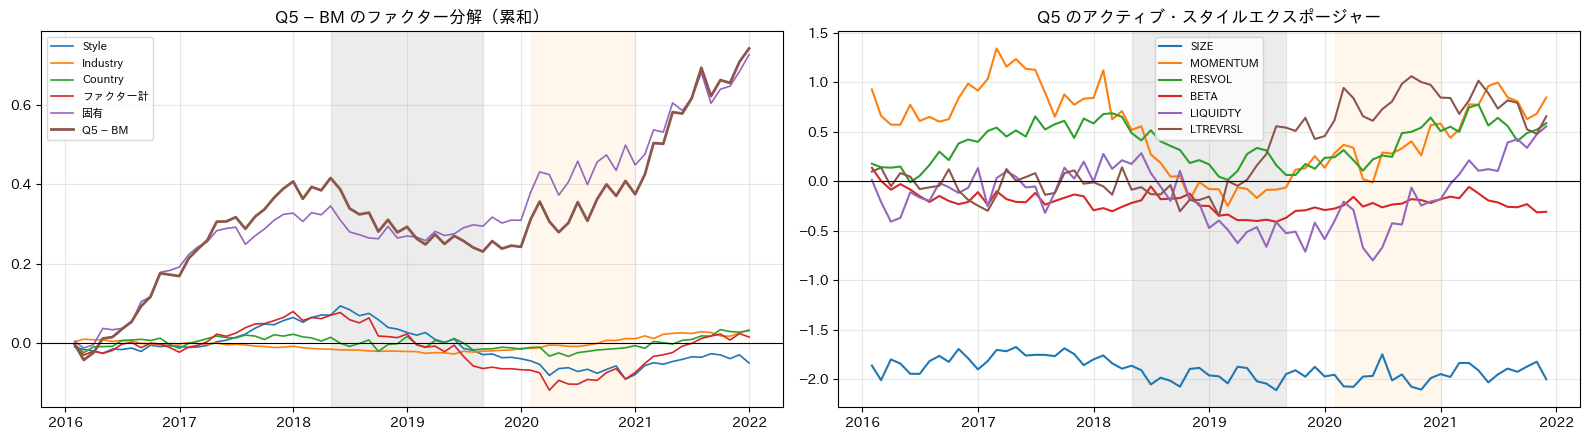

In [5]:
fl = store.factor_list(RISK_MODEL)
fr = store.factor_return(RISK_MODEL)
sym = dict(zip(fl["id"], fl["symbol"]))
grp = dict(zip(fl["id"], fl["group"].map({"Risk Indices": "Style", "Industries": "Industry", "Countries": "Country", "Currencies": "Currency"}).fillna("Market")))
q = q_main["drtn"]
w5 = q.weights[q.top].fillna(0)
act = w5 - bm_w.reindex(index=w5.index, columns=w5.columns).fillna(0)
exc = decomp["drtn"][MAIN]["Q5 − BM"]
rows, per, expo = {}, {}, {}
for t in act.loc["2015-12":"2021-11"].index:
    X = store.exposure(RISK_MODEL, t)
    ax_ = X.T.fillna(0) @ act.loc[t].reindex(X.index).fillna(0)
    nxt = fr.index[fr.index.searchsorted(t, side="right")]
    c = ax_ * fr.loc[nxt].reindex(ax_.index).fillna(0)
    per[nxt] = c
    g = c.groupby(pd.Series(c.index.map(grp), index=c.index)).sum().to_dict()
    g["ファクター計"] = c.sum()
    g["Q5 − BM"] = exc.get(nxt, np.nan)
    g["固有"] = g["Q5 − BM"] - g["ファクター計"]
    rows[nxt] = g
    expo[t] = ax_
G = pd.DataFrame(rows).T
P = pd.DataFrame(per).T.rename(columns=sym)
EX = pd.DataFrame(expo).T.rename(columns=sym)
cols = ["Style", "Industry", "Country", "ファクター計", "固有", "Q5 − BM"]
print(f"窓 {WINDOW[0]}〜{WINDOW[1]} の合計")
display(G.loc[WINDOW[0]:WINDOW[1], cols].sum().round(3).to_frame("寄与").T)
pw = P.loc[WINDOW[0]:WINDOW[1]].sum().sort_values()
print("窓のファクター別寄与（下位 8 / 上位 5）")
display(pd.concat([pw.head(8), pw.tail(5)]).round(3).to_frame("寄与").T)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
v = G.loc[VIEW[0]:VIEW[1]]
for c in cols:
    axes[0].plot(v.index, v[c].cumsum(), label=c, linewidth=2 if c == "Q5 − BM" else 1.2)
axes[0].axhline(0, color="k", linewidth=0.8)
shade(axes[0])
axes[0].set_title("Q5 − BM のファクター分解（累和）")
axes[0].legend(fontsize=8)
e = EX.loc[VIEW[0]:VIEW[1], ["SIZE", "MOMENTUM", "RESVOL", "BETA", "LIQUIDTY", "LTREVRSL"]]
for c in e.columns:
    axes[1].plot(e.index, e[c], label=c)
axes[1].axhline(0, color="k", linewidth=0.8)
shade(axes[1])
axes[1].set_title("Q5 のアクティブ・スタイルエクスポージャー")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 4. 超大型株のアンダーウェイトと銘柄別寄与

### 4.1 BM 上位 10 銘柄の保有

In [6]:
rows = []
for t in w5.loc[VIEW[0]:VIEW[1]].index:
    i = bm_w.loc[t].nlargest(10).index
    rows.append({"date": t, "上位 10 の BM ウェイト": bm_w.loc[t, i].sum(), "Q5 の上位 10 ウェイト": w5.loc[t, i].sum(), "上位 10 のうち Q5 にある数": int((w5.loc[t, i] > 0).sum()), "Q5 銘柄数": int((w5.loc[t] > 0).sum())})
T = pd.DataFrame(rows).set_index("date")
display(T.groupby(T.index.year).mean().round(3))

,上位 10 の BM ウェイト,Q5 の上位 10 ウェイト,上位 10 のうち Q5 にある数,Q5 銘柄数
date,,,,
2016,0.489,0.011,0.667,63.333
2017,0.443,0.010,0.667,66.750
2018,0.485,0.021,1.500,70.833
2019,0.527,0.026,1.750,67.583
2020,0.546,0.017,1.083,62.333
2021,0.476,0.002,0.167,71.833


### 4.2 窓の銘柄別寄与

寄与 = 前月末アクティブウェイト × (銘柄リターン − BM リターン) の合計。アクティブウェイトの合計は 0 なので、合計は Q5 − BM に一致する。

In [7]:
r = rets["drtn"]
bmr_d = portfolio_returns(bm, r)
contrib = (act.shift(1).reindex(r.index) * r.sub(bmr_d, axis=0)).loc[WINDOW[0]:WINDOW[1]]
print("寄与の合計:", round(float(contrib.sum().sum()), 3), "／ Q5 − BM の窓合計:", round(float(decomp["drtn"][MAIN]["Q5 − BM"].loc[WINDOW[0]:WINDOW[1]].sum()), 3))
tot = contrib.sum().sort_values()
u = pd.read_pickle("../../data/universe/201812.pkl").set_index("bid")
names = u["name"]
gics = store.alpha("attributes/gics", START, END)
sector = (gics.loc["2018-12-31"] // 1_000_000).map(SECTOR_NAMES)
meta = lambda idx: pd.DataFrame({"銘柄": names.reindex(idx), "セクター": sector.reindex(idx), "寄与": tot.reindex(idx), "平均アクティブウェイト": act.loc["2018-04":"2019-07"].mean().reindex(idx), "窓の累積リターン": (1 + r.loc[WINDOW[0]:WINDOW[1]]).prod().reindex(idx) - 1, "BM の累積リターン": float((1 + bmr_d.loc[WINDOW[0]:WINDOW[1]]).prod() - 1)})
print("寄与の下位 12")
display(meta(tot.head(12).index).round(3))
print("寄与の上位 8")
display(meta(tot.tail(8).index[::-1]).round(3))
top10_set = set().union(*[set(bm_w.loc[t].nlargest(10).index) for t in bm_w.loc["2018-04":"2019-07"].index])
is_top = tot.index.isin(top10_set)
uw_ = act.loc["2018-04":"2019-07"].mean().reindex(tot.index) > 0
print("区分別の寄与合計:", {"BM 上位 10（アンダーウェイト）": round(tot[is_top].sum(), 3), "Q5 保有（上位 10 以外）": round(tot[~is_top & uw_].sum(), 3), "その他のアンダーウェイト": round(tot[~is_top & ~uw_].sum(), 3)})

寄与の合計: -0.184 ／ Q5 − BM の窓合計: -0.185
寄与の下位 12


,銘柄,セクター,寄与,平均アクティブウェイト,窓の累積リターン,BM の累積リターン
INDABV1,RELIANCE_INDUSTRIES,エネルギー,-0.027,-0.104,0.311,0.016
INDAVD1,INFOSYS,情報技術,-0.026,-0.075,0.435,0.016
INDAGI1,HOUSING_DEV_FINANCE_CORP,金融,-0.014,-0.097,0.171,0.016
INDDTA1,TATA_CONSULTANCY,情報技術,-0.014,-0.049,0.312,0.016
INDHHK1,CARE_RATINGS,金融,-0.010,0.012,-0.556,0.016
INDDMD1,GRUH_FINANCE,金融,-0.010,0.007,-0.232,0.016
INDBSF1,GRAPHITE_INDIA,資本財,-0.009,0.008,-0.564,0.016
INDBOT1,ICICI_BANK,金融,-0.009,-0.026,0.451,0.016
INDCWV1,AXIS_BANK,金融,-0.008,-0.037,0.285,0.016
INDDXL1,IIFL_HOLDINGS,金融,-0.008,0.004,-0.674,0.016


寄与の上位 8


,銘柄,セクター,寄与,平均アクティブウェイト,窓の累積リターン,BM の累積リターン
INDDVF1,YES_BANK,金融,0.016,-0.012,-0.831,0.016
INDACB1,TATA_MOTORS,一般消費財,0.011,-0.010,-0.657,0.016
INDAGW1,BATA_INDIA,一般消費財,0.011,0.012,0.940,0.016
INDEXA1,VINATI_ORGANICS,素材,0.009,0.011,1.377,0.016
INDDSF1,MARUTI_SUZUKI_INDIA,一般消費財,0.008,-0.024,-0.290,0.016
INDABI1,MAHINDRA_&_MAHINDRA,一般消費財,0.008,-0.018,-0.381,0.016
INDAPP1,MERCK,ヘルスケア,0.008,0.008,0.472,0.016
INDDVM1,INDIABULLS_HOUSING_FIN,金融,0.007,-0.007,-0.624,0.016


区分別の寄与合計: {'BM 上位 10（アンダーウェイト）': -0.081, 'Q5 保有（上位 10 以外）': -0.176, 'その他のアンダーウェイト': 0.072}


### 4.3 セクター別寄与（窓）

In [8]:
sec_panel = (gics.reindex(index=act.index, columns=act.columns) // 1_000_000).apply(lambda c: c.map(SECTOR_NAMES))
long = pd.DataFrame({"c": contrib.stack(), "s": sec_panel.shift(1).reindex(contrib.index).stack()}).dropna()
sec_c = long.groupby("s")["c"].sum().sort_values()
aw = pd.DataFrame({"a": act.loc["2018-04":"2019-07"].stack(), "s": sec_panel.loc["2018-04":"2019-07"].stack()}).dropna()
sec_aw = aw.groupby([aw.index.get_level_values(0), "s"])["a"].sum().groupby("s").mean()
display(pd.DataFrame({"寄与": sec_c, "平均アクティブウェイト": sec_aw.reindex(sec_c.index)}).round(3).T)

s,資本財,情報技術,金融,エネルギー,素材,不動産,生活必需品,一般消費財,通信,公益,ヘルスケア
寄与,-0.076,-0.058,-0.041,-0.025,-0.024,-0.002,-0.002,0.004,0.009,0.012,0.019
平均アクティブウェイト,0.114,-0.102,-0.087,-0.121,0.080,0.015,-0.037,0.071,0.016,0.004,0.047


## 5. 規模別に見たシグナル（H2）

ユニバースを前月末の時価総額で 3 分割し、各グループ内で 5 分位を作る。グループ内の Q5 − Q1 と Q5 − グループ平均（等ウェイト、drtn、年率）。

In [9]:
r = rets["drtn"]
rank = univ.rank(axis=1, pct=True)
buckets = {"大型（上位 1/3）": rank > 2 / 3, "中型": (rank > 1 / 3) & (rank <= 2 / 3), "小型（下位 1/3）": rank <= 1 / 3}
PER = {"2009-01〜2018-04": ("2009-01", "2018-04"), "窓 2018-05〜2019-08": WINDOW, "2020": ("2020-01", "2020-12"), "2021-01〜2026-07": ("2021-01", "2026-07")}
rows = {}
for b, m in buckets.items():
    uu = univ.where(m)
    qb = quantile_analysis(scores[MAIN], r, uu, 5)
    bw = uu.notna().astype(float).where(uu.notna())
    bw = bw.div(bw.sum(axis=1), axis=0)
    br = portfolio_returns(bw, r)
    sel = (qb.returns[qb.top] - br).dropna()
    for p, (a, z) in PER.items():
        rows[(b, "Q5 − Q1")] = rows.get((b, "Q5 − Q1"), {}) | {p: qb.returns["spread"].loc[a:z].mean() * 12}
        rows[(b, "Q5 − グループ平均")] = rows.get((b, "Q5 − グループ平均"), {}) | {p: sel.loc[a:z].mean() * 12}
display(pd.DataFrame(rows).T.round(3))

2009-01〜2018-04  窓 2018-05〜2019-08   2020  2021-01〜2026-07
大型（上位 1/3） Q5 − Q1                0.178              0.105 -0.035            0.054
           Q5 − グループ平均            0.095              0.026  0.046            0.046
中型         Q5 − Q1                0.196              0.320  0.145            0.143
           Q5 − グループ平均            0.109              0.068 -0.009            0.072
小型（下位 1/3） Q5 − Q1                0.246              0.251 -0.019            0.303
           Q5 − グループ平均            0.131              0.130  0.049            0.157

## 6. 2020 年: コロナ後の反発でシグナルが負けた（H3）

2020 年は構造（EW − BM）はプラスだったが、comp_ew の Q5 − Q1 がほぼゼロ。月次の分位リターンとスリーブ別、ファクターリターンを見る。

In [10]:
r = rets["drtn"]
q = q_main["drtn"]
m = q.returns.loc["2020-01":"2020-12"].copy()
print("comp_ew の分位別月次リターン（drtn、Q5 = 最上位）")
display(m.round(3))
print("スリーブ別 Q5 − Q1（月次、drtn）")
display(pd.DataFrame({n: d["Q5 − Q1"].loc["2020-01":"2020-12"] for n, d in decomp["drtn"].items()}).round(3))
ids = {v: k for k, v in sym.items()}
f = fr.loc["2020-01":"2020-12", [ids[s] for s in ["MOMENTUM", "LTREVRSL", "BETA", "LIQUIDTY", "RESVOL", "SIZE"]]].rename(columns=sym)
print("GEMLT ファクターリターン（2020 年、月次）")
display(f.round(3))
p20 = P.loc["2020-04":"2020-12"].sum().sort_values()
print("2020-04〜12 の Q5 − BM ファクター別寄与（下位 6 / 上位 4）")
display(pd.concat([p20.head(6), p20.tail(4)]).round(3).to_frame("寄与").T)

comp_ew の分位別月次リターン（drtn、Q5 = 最上位）


,Q1,Q2,Q3,Q4,Q5,spread
2020-01-31,0.024,0.047,0.045,0.066,0.061,0.037
2020-02-29,-0.135,-0.066,-0.065,-0.057,-0.018,0.117
2020-03-31,-0.363,-0.300,-0.291,-0.271,-0.265,0.098
2020-04-30,0.258,0.154,0.138,0.162,0.129,-0.129
2020-05-31,-0.012,0.001,-0.022,0.009,0.003,0.015
2020-06-30,0.181,0.145,0.104,0.064,0.119,-0.063
2020-07-31,0.044,0.040,0.053,0.079,0.048,0.004
2020-08-31,0.117,0.103,0.092,0.063,0.073,-0.044
2020-09-30,-0.034,-0.000,0.011,0.034,0.046,0.080
2020-10-31,0.014,-0.002,0.000,0.004,-0.013,-0.027


スリーブ別 Q5 − Q1（月次、drtn）


,comp_ew,sleeve_a（リビジョン）,sleeve_b（モメンタム+CGO）,sleeve_d（規律）,hc_all
2020-01-31,0.037,0.059,0.036,-0.004,-0.031
2020-02-29,0.117,0.061,0.097,0.025,0.039
2020-03-31,0.098,0.038,0.053,0.091,0.141
2020-04-30,-0.129,-0.062,-0.129,0.001,0.057
2020-05-31,0.015,0.038,-0.012,0.019,-0.004
2020-06-30,-0.063,-0.030,-0.099,-0.056,-0.119
2020-07-31,0.004,0.011,0.032,0.002,0.023
2020-08-31,-0.044,-0.073,-0.075,-0.002,-0.057
2020-09-30,0.080,0.039,0.071,0.031,0.097
2020-10-31,-0.027,0.010,-0.019,-0.018,0.018


GEMLT ファクターリターン（2020 年、月次）


,MOMENTUM,LTREVRSL,BETA,LIQUIDTY,RESVOL,SIZE
2020-01-31,0.013,-0.003,-0.018,-0.001,-0.007,0.004
2020-02-29,0.011,-0.006,-0.003,0.001,-0.002,0.003
2020-03-31,0.003,-0.010,-0.029,-0.016,-0.010,0.021
2020-04-30,0.003,-0.003,0.031,0.013,0.020,-0.013
2020-05-31,0.014,-0.005,0.016,0.007,0.006,-0.004
2020-06-30,0.006,0.006,0.013,0.016,0.016,-0.001
2020-07-31,0.022,0.003,-0.001,0.006,-0.002,-0.002
2020-08-31,0.001,-0.002,0.017,0.004,-0.002,-0.001
2020-09-30,0.007,-0.003,-0.002,-0.006,0.001,-0.002
2020-10-31,0.001,0.000,0.006,-0.000,0.006,-0.004


2020-04〜12 の Q5 − BM ファクター別寄与（下位 6 / 上位 4）


factor_id,LIQUIDTY,BETA,LTREVRSL,INTERNET,SOFTWARE,EARNYILD,OILGAS,RESVOL,IND,SIZE
寄与,-0.03,-0.028,-0.013,-0.009,-0.006,-0.004,0.012,0.024,0.027,0.051


## 所見

**結論**: 2018-05〜2019-08 の Q5 の負けはシグナルではなく**市場構造**（超大型株への集中と中小型株の急落）。2020-03 の落ち込みも同じ構造による。
一方 **2020-04〜12 はシグナル自体が負けた**（コロナ後の低品質・高ベータ株の反発）。ただしこの期間は中小型の反発で Q5 − BM はプラスに見えるため、累積図では隠れている。

**1. 構造と選択の分解（drtn、窓 2018-05〜2019-08 の合計）**

| | Q5 − BM | 構造（EW ユニバース − BM） | 選択（Q5 − EW ユニバース） | Q5 − Q1 |
| --- | --- | --- | --- | --- |
| comp_ew | −18.5% | −29.3% | +10.8% | +29.3% |
| sleeve_a（リビジョン） | −20.9% | −29.3% | +8.5% | +16.5% |
| sleeve_b（モメンタム+CGO） | −12.0% | −29.3% | +17.3% | +38.9% |
| sleeve_d（規律） | −24.7% | −29.3% | +4.7% | +8.0% |
| hc_all | −16.0% | −29.3% | +13.3% | +23.2% |

どのスコアも構造で −29% を負い、選択はすべてプラス（年率でも comp_ew は 2018 年 +9.6%、2019 年 +9.5% と平常どおり）。H2（シグナル失効）は否定される。

**2. 市場構造（H1）**: 2018 年は BM 時価加重 +1.5% に対し BM 等ウェイト −6.8%。BM 上位 10 は +17.4%、それ以外は −11.0%、ユニバース最小 5 分位は −26.3%。
2019 年も上位 10 が +20.8%、それ以外 −0.3%。上位 10 の BM ウェイトは 48% → 53% に上がった。2014〜2023 年で時価加重が等ウェイトを大きく上回ったのはこの 2 年だけ。
LTCG 課税の再導入、SEBI のカテゴリ再編（ラージキャップ投信の上位 100 社 80% 義務）、IL&FS 危機が重なった局面。

**3. Q5 の構造的なベット**: Q5 は BM 上位 10 銘柄を合計 2% 程度しか持たず（BM は 48〜53%）、アクティブ SIZE は常に −2.0 前後。
ファクター分解では Style −10.0%（うち SIZE −8.5%、RESVOL −1.7%）、市場ベータ（Country）−3.0%、固有 −5.1%。
固有リターン（srtn）でも EW ユニバース − BM は −10.3% で、SIZE ファクターだけでは中小型の急落を説明しきれない。

**4. 銘柄とセクター**: BM 上位 10 のアンダーウェイトで −8.1%（Reliance −2.7%、Infosys −2.6%、HDFC −1.4%、TCS −1.4%、ICICI −0.9%、Axis −0.8%）。
Q5 の保有銘柄（上位 10 以外）は BM 比 −17.6%。中小型が BM（窓で +1.6%）より下げ、IL&FS 危機で売られた金融（CARE Ratings −56%、IIFL −67%、Gruh −23%）や電極サイクルが反転した Graphite India（−56%）が目立つ。
セクターでは資本財（オーバーウェイト +11%）−7.6%、情報技術（アンダーウェイト −10%）−5.8%、金融 −4.1%。

**5. 規模別に見てもシグナルは生きている**: 窓の Q5 − Q1 は中型 32.0%、小型 25.1% で平常期（19.6%、24.6%）と同等以上。大型だけ 10.5%（平常期 17.8%）に落ちた。上昇した超大型株をシグナルが拾えていないため。

**6. 時価総額ウェイトの Q5 も負けた**: 窓で −12.1% = 構造（5% 上限の時価総額ウェイトのユニバース）−7.7% + 選択 −4.4%。上限で超大型株を持ちきれないことと、大型内の選択が弱かったことの両方。

**7. 2020 年はシグナル自体の負け（H3）**: comp_ew の Q5 − Q1 は年間 +0.7%。暴落の 2〜3 月は +11.7%、+9.8% と守ったが、4 月 −12.9%、6 月 −6.3%、8 月 −4.4%、11 月 −4.9%、12 月 −3.1%。
4 月は Q1 が +25.8%（Q5 +12.9%）。スリーブ別ではモメンタムが最も負け（4 月 −12.9%、6 月 −9.9%、11 月 −7.9%）、リビジョンは軽く、規律はほぼ横ばい。
ファクターでは BETA（4 月 +3.1%、11 月 +4.3%）、LIQUIDTY、RESVOL が上がり、11 月にはワクチン報道で MOMENTUM が −3.9%。
4〜12 月の Q5 − BM は LIQUIDTY −3.0%、BETA −2.8%、長期リバーサル −1.3% を負い、SIZE +5.1%（中小型反発）で相殺した。

**含意**

- **評価**: 「Q5 EW − BM」はサイズ・等ウェイトのベットとシグナルを混ぜている。composite の再構築で素材を比べるときは、選択（Q5 − EW ユニバース）、Q5 − Q1、規模内の分位で判断する。
- **ポートフォリオ**: 同じ構造的ベット（超大型のアンダーウェイト、アクティブ SIZE −2）は最適化後のポートフォリオにも出ており、前回分析した bax の 2018-04〜2019-04 のドローダウンと同じ現象。
  抑えるなら SIZE エクスポージャー制約や超大型株のアクティブ下限の緩和だが、等ウェイトが勝つ年（2014、2016、2021、2023）の超過も削る。
- **2020 型のリスク**: 急反発局面のモメンタム・クラッシュ。再構築ではモメンタムのウェイトや、ボラティリティに応じた縮小を検討する価値がある。